<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Seasonality ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [1]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
#import plot_psd1Xglobal1 as pp2X
import cum_sp_onl_season_v2 as cs
import importlib

importlib.reload(cs)
import position_function as pf
importlib.reload(pf)

CPU times: user 1.51 s, sys: 305 ms, total: 1.82 s
Wall time: 2.28 s


<module 'cum_sp_onl_season_v2' from '/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v2.py'>

## **Map plot functions**

In [2]:

def plot_fig(ax,imodel,lon_edges,lat_edges,ZW,valmin,valmax,model,posx,posy,abc):
    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].contourf(
        lon_edges,
        lat_edges,
        np.squeeze((ZW[imodel,:,:])),
        np.arange(valmin,valmax,0.25),
        cmap='hsv',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].set_title(abc + model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

In [3]:


def plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,posx,posy,abc,box_pos,box_neg):
    #norm = mcolors.LogNorm(vmin=valmin, vmax=valmax)

    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].pcolormesh(
        lon_edges,
        lat_edges,
        np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
        vmin=valmin,vmax=valmax,
        cmap='seismic',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].text(30, 60,f"Boxes >1: {box_pos[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].text(30, 40,f"Boxes <1: {box_neg[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].set_title(abc + model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

## **Load boxes position**

In [4]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region



North boxes: 93
South boxes: 189


In [4]:
# NOT MODIFY

# Reading boxes position over the entire global ocean
roi = {
        "lon_min": -180,
        "lon_max": 180,
        "lat_min": -90,
        "lat_max": 90
}
pos_reg=[-180, -90, 180, 90]

with open("mostly_ocean_boxes_filtered.geojson") as f:
    data = json.load(f)

roi_poly = box(roi["lon_min"], roi["lat_min"],
               roi["lon_max"], roi["lat_max"])

selected = [] 

for feature in data["features"]:
    poly = shape(feature["geometry"])
    if poly.intersects(roi_poly):
        selected.append(poly)

# Selecting north and south boxes 

north_boxes = []
south_boxes = []

for i, feature in enumerate(data["features"]):

    coords = feature["geometry"]["coordinates"][0]
    lats = [c[1] for c in coords]
    lat_center = sum(lats) / len(lats)
    if lat_center >= 0:
        north_boxes.append(i)
    else:
        south_boxes.append(i)

print("North boxes:", len(north_boxes))
print("South boxes:", len(south_boxes))


North boxes: 93
South boxes: 189


## **Load Spectrum**

In [5]:
#Define Wavelength range
min_wavelength=50
max_wavelength=150
models=["GLO12V4","GLO36V1","GLO36V1NOTIDE","NOC12","NOC025",'LLC4320',"SWOT"]

m_slopeW,m_slopeS,s_slopeW,s_slopeS=cs.season_slope(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,"https://minio.dive.edito.eu/","JFM","JAS")

m_slopeW2,m_slopeS2=cs.cum_sum(m_slopeW,m_slopeS,models)
s_slopeW2,s_slopeS2=cs.cum_sum(s_slopeW,s_slopeS,models)
#Ver otras escalars



/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v2.py:169: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM)


## **Plotting**
  

In [6]:
# Estimating how many boxes are >/< to 1
box_pos=np.zeros((7))
box_neg=np.zeros((7))

for imodel in range(7):
    box_neg[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]<1)[0])
    box_pos[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]>1)[0])


print(box_pos)
print(box_neg)


[ 68. 114. 112.  81. 155. 146. 115.]
[212. 166. 168. 199. 125. 134. 165.]


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_5968/1768249982.py:6: RuntimeWarning: invalid value encountered in divide
  box_neg[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]<1)[0])
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_5968/1768249982.py:7: RuntimeWarning: invalid value encountered in divide
  box_pos[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]>1)[0])


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_5968/2532655704.py:58: RuntimeWarning: Mean of empty slice
  ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_5968/2532655704.py:71: RuntimeWarning: Mean of empty slice
  ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])


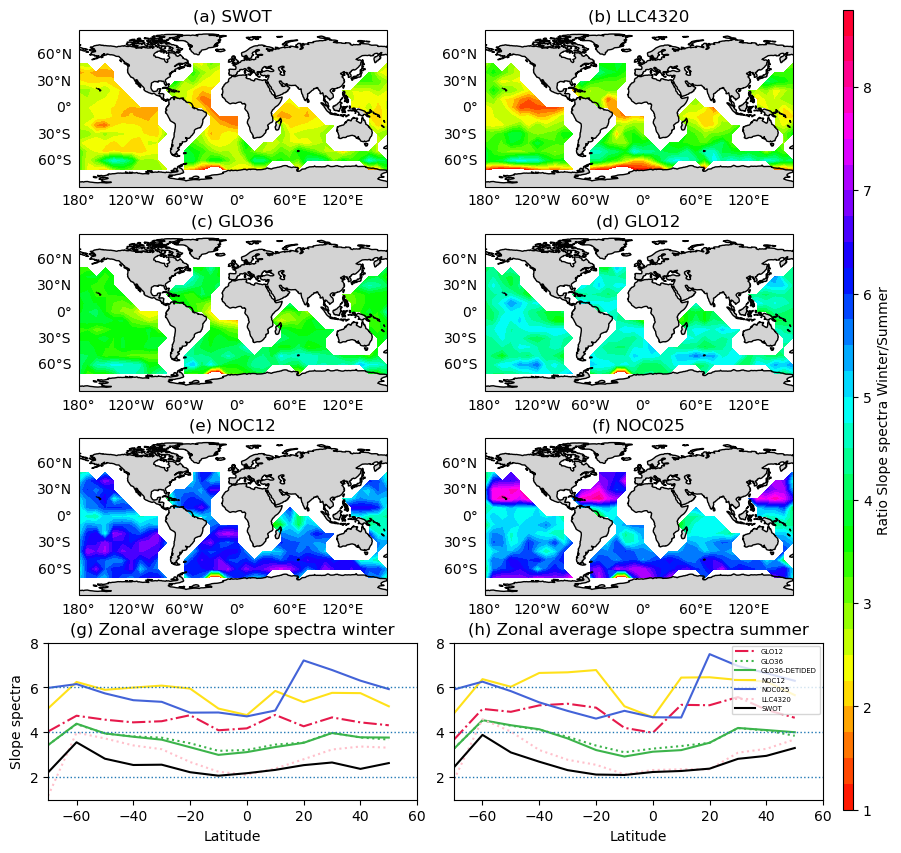

In [14]:
model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
#colors = ["#E6194B", "#3CB44B",  "#FFE119", "#4363D8",  "pink", "k", "#3CB44B"]
#lsty=['dashed','dotted','solid','solid','dotted','solid','solid']
lsty=['dashdot','dotted','solid','solid','solid','dotted','solid','solid']

colors = [ "#E6194B", "#3CB44B", "#3CB44B", "#FFE119",  "#4363D8",  "pink", "k"]        #"#F58231",  # orange
        #
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=1
valmax=9

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

fig = plt.figure(figsize=(10, 10))
fig.subplots_adjust(wspace=0.1, hspace=0.3)

ax = np.empty((4, 2), dtype=object)

for r in range(4):
    for c in range(2):
        idx = r * 2 + c + 1

        if r < 3:  # first two rows are maps
            ax[r, c] = fig.add_subplot(
                4, 2, idx,
                projection=ccrs.PlateCarree()
            )
        else:      # last two rows are regular axes
            ax[r, c] = fig.add_subplot(4, 2, idx)
            
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,1,'(f) ')

#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Ratio Slope spectra Winter/Summer")

for i in range(len(colors)):
    ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
#ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2,axis=2).T,label=model,color=colors)
ax[3,0].set_xlabel("Latitude")
ax[3,0].set_ylabel("Slope spectra")
ax[3,0].set_title('(g) Zonal average slope spectra winter')
ax[3,0].set_ylim([1,8])
ax[3,0].set_xlim([-70,60])
ax[3,0].axhline(y=2, linestyle=':', linewidth=1)
ax[3,0].axhline(y=4, linestyle=':', linewidth=1)
ax[3,0].axhline(y=6, linestyle=':', linewidth=1)
#ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2,axis=2).T,label=model,color=colors)

for i in range(len(colors)):
    ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
ax[3,1].set_title('(h) Zonal average slope spectra summer')
ax[3,1].set_xlabel("Latitude")
ax[3,1].legend(loc='upper right', handlelength=3, fontsize=5)
ax[3,1].set_ylim([1,8])
ax[3,1].set_xlim([-70,60])
ax[3,1].axhline(y=2, linestyle=':', linewidth=1)
ax[3,1].axhline(y=4, linestyle=':', linewidth=1)
ax[3,1].axhline(y=6, linestyle=':', linewidth=1)
plt.savefig("FigV2/winterslope_season_zonalaverage_V2_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



In [14]:
i=0
np.nanmean(m_slopeW2[i,:,:],axis=1)

/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_4577/554637832.py:2: RuntimeWarning: Mean of empty slice
  np.nanmean(m_slopeW2[i,:,:],axis=1)


array([       nan,        nan, 4.04104513, 4.74159281, 4.56487776,
       4.44631634, 4.49663786, 4.76496458, 4.09351568, 4.17903084,
       4.77770456, 4.27051357, 4.66738307, 4.44518678, 4.31634769,
              nan,        nan,        nan])

/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_12268/1568261220.py:9: Run

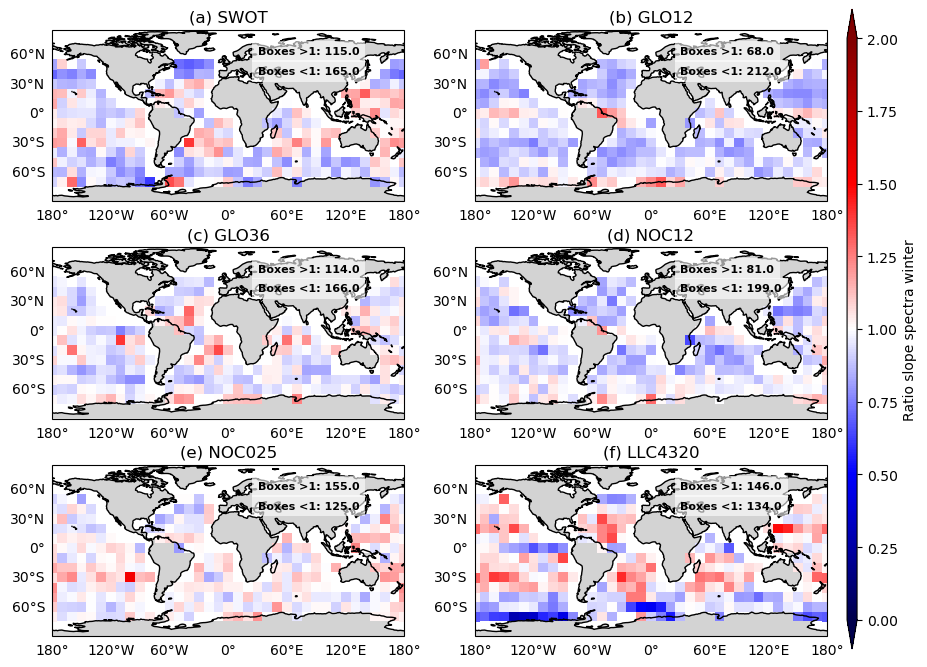

In [18]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=2
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,0,0,'(a) ',box_pos,box_neg)
imodel=0
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,0,1,'(b) ',box_pos,box_neg)
imodel=1
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,1,0,'(c) ',box_pos,box_neg)
imodel=2
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,1,1,'(d) ',box_pos,box_neg)
imodel=3
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,2,0,'(e) ',box_pos,box_neg)
imodel=4
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,2,1,'(f) ',box_pos,box_neg)



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Ratio slope spectra winter")
plt.savefig("FigV2/ratioslope_season_model_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



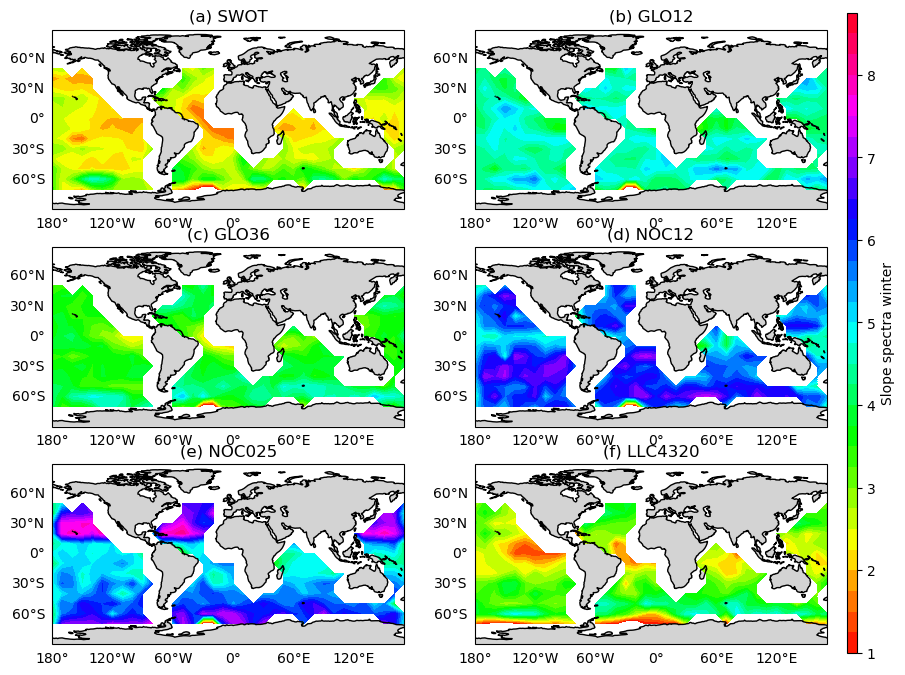

In [81]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=1
valmax=9
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/slope_season_model_winter_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



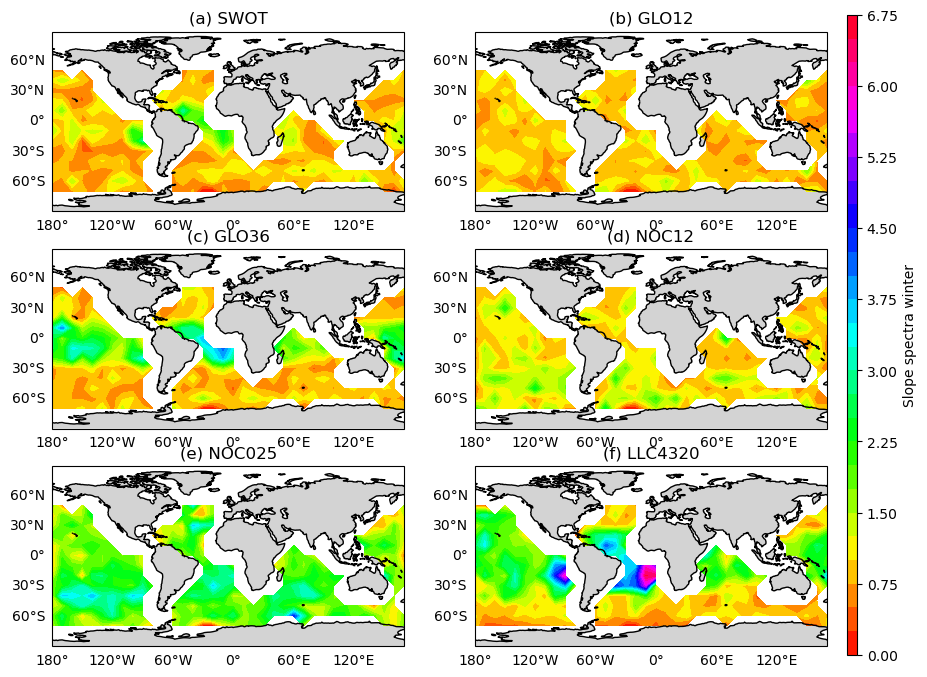

In [88]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=7
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/std_slope_season_model_winter_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



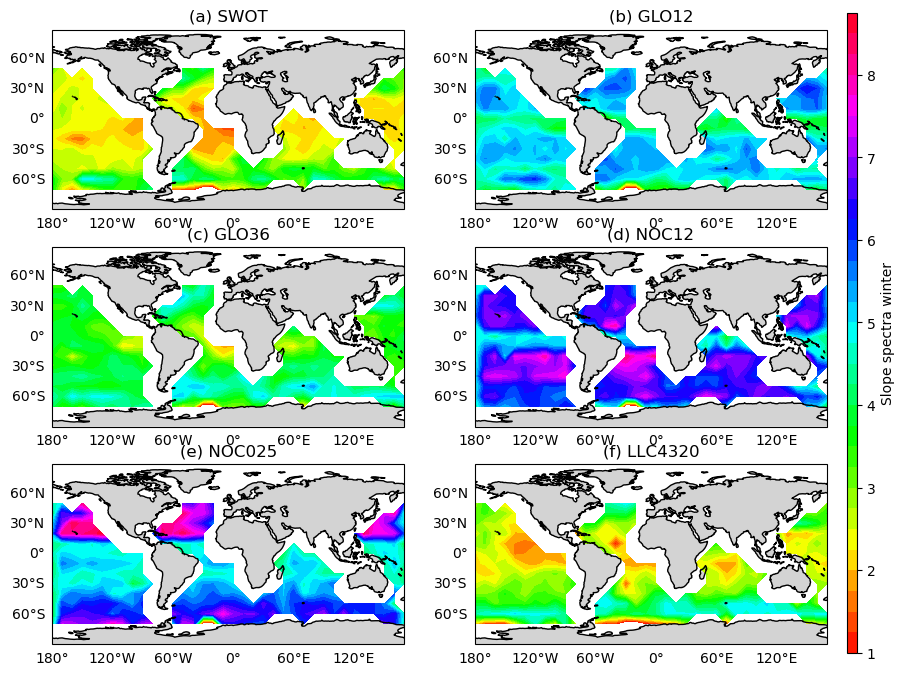

In [82]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=1
valmax=9
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,0,0,'(a) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,1,0,'(c) ')
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/slope_season_model_summer_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



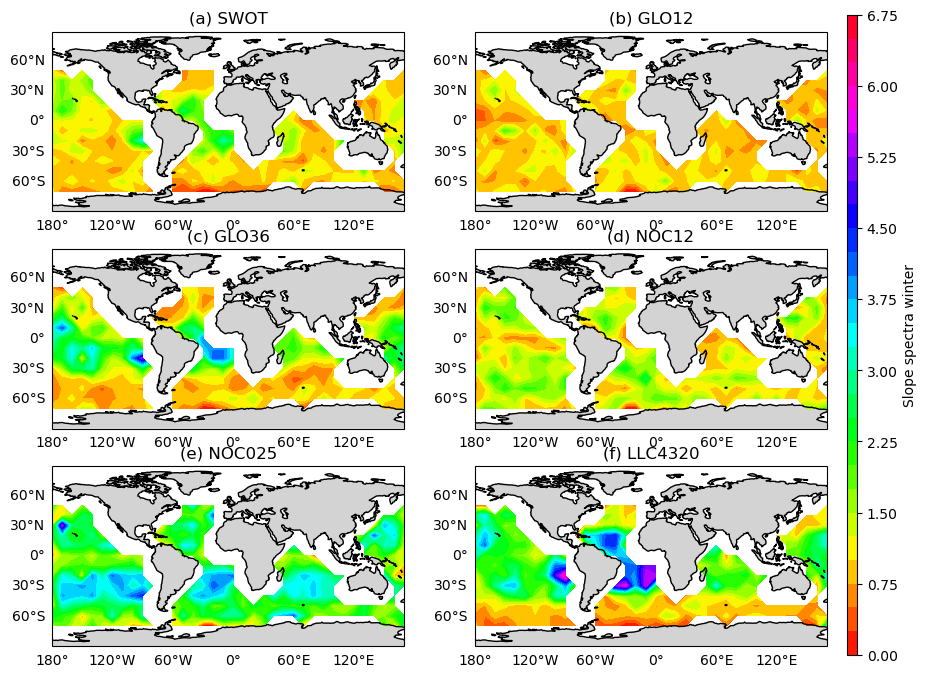

In [89]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=7
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,0,0,'(a) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,1,0,'(c) ')
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/std_slope_season_model_summer_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



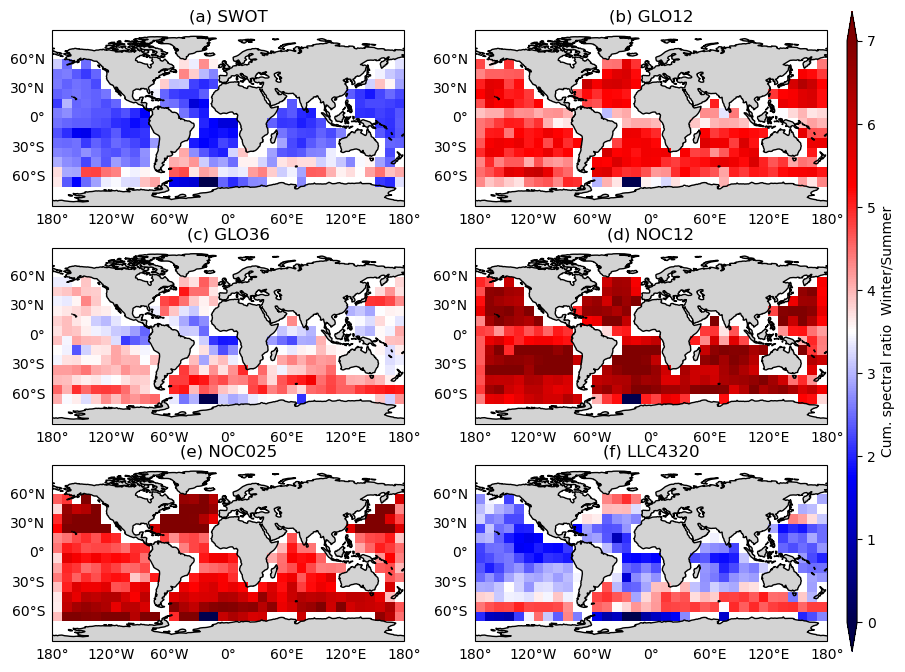

In [10]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=7
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,0,0,'(a) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,1,0,'(c) ')
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,m_slopeS2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Cum. spectral ratio  Winter/Summer")
#plt.savefig("FigV2/cum_season_model_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



In [11]:
with open("mostly_ocean_boxes_filtered.geojson") as f:
    data = json.load(f)

latboxes = []
latpos=np.arange(-70,61,10)

for i, feature in enumerate(data["features"]):
    if (i!=14) and (i!=15):
        coords = feature["geometry"]["coordinates"][0]
        first_lat = coords[0][1]  # First coord [lon, lat] → lat is index 1
        latboxes.append(first_lat)

latindex=[]
for i in latpos:
    latindex.append(np.where(latboxes==i))

print(latindex[0])

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22]),)


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWarning: invalid value encountered in divide
  np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_6080/4209014050.py:7: RuntimeWa

NameError: name 'R0' is not defined

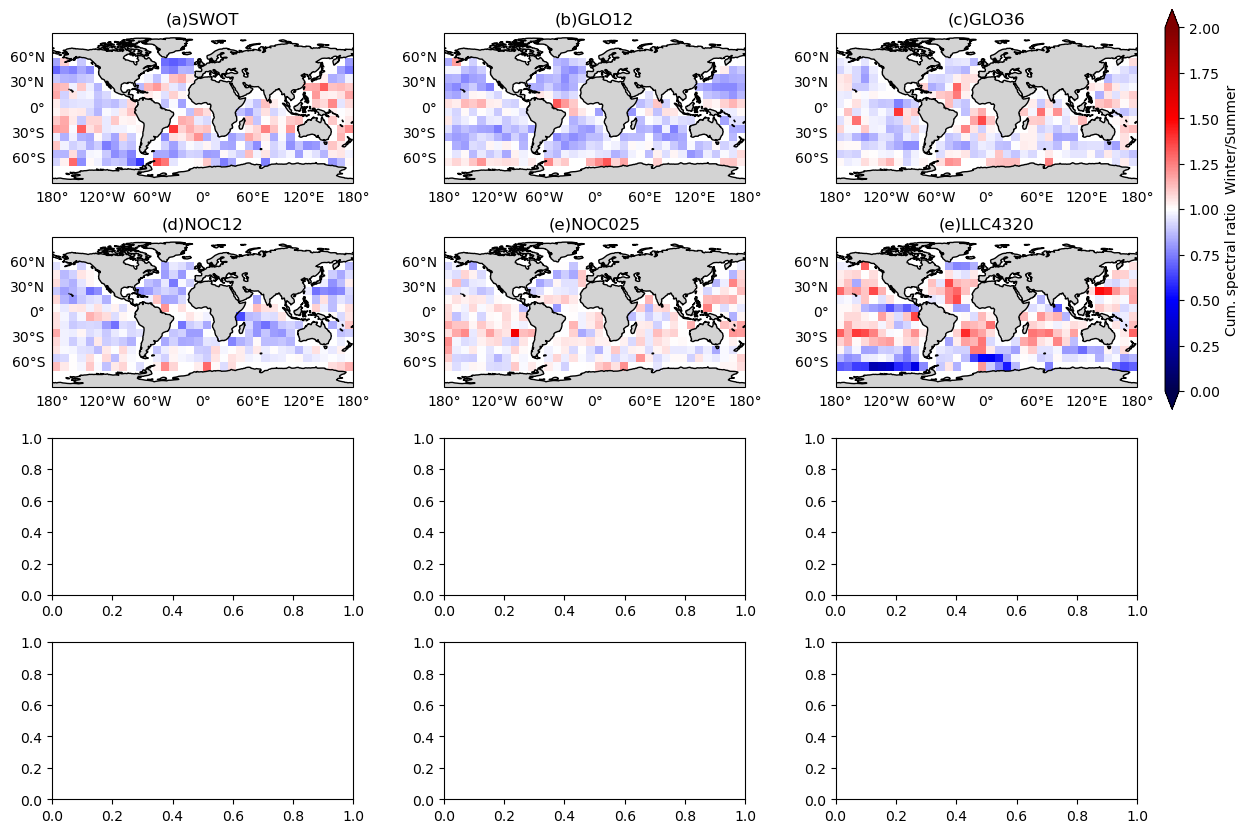

In [14]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

ZW=m_slopeW2
ZS=m_slopeS2
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
fig = plt.figure(figsize=(14, 10))
fig.subplots_adjust(wspace=0.3, hspace=0.3)

ax = np.empty((4, 3), dtype=object)

for r in range(4):
    for c in range(3):
        idx = r * 3 + c + 1

        if r < 2:  # first two rows are maps
            ax[r, c] = fig.add_subplot(
                4, 3, idx,
                projection=ccrs.PlateCarree()
            )
        else:      # last two rows are regular axes
            ax[r, c] = fig.add_subplot(4, 3, idx)


valmin=0
valmax=2
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,0,0,"(a)")
imodel=0
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,0,1,"(b)")
imodel=1
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,0,2,"(c)")
imodel=2
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,1,0,"(d)")
imodel=3
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,1,1,"(e)")
imodel=4
ax, mesh=plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,1,2,"(e)")

#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.5, 0.01, .4])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Cum. spectral ratio  Winter/Summer")
#plt.savefig("FigV2/cum_season_model_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)


#------------------------------
RM = ZW
F2 = F#[::20]
Wl=F2[0] #wavelength to interpolate for mean


Fb1=np.zeros((len(Wl),14,6))

for imodel in range(6):
    R=RM[imodel]
    for i in range(len(latindex)): #len(R)):
        k=0
        pos=latindex[i][0]
        Fb0=np.zeros((len(Wl)))
        for ilat in pos:
            Fb0=Fb0+np.interp(Wl,F2[ilat], R[ilat])
            k=k+1
        Fb1[:,i,imodel]=Fb0/k


mymin=1e1
mymax=1e-1
norm = mcolors.LogNorm(vmin=mymin, vmax=mymax)
imodel=5
pc=ax[2,0].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax[2,0].set_ylabel("Wavelength")
#ax[2,0].plot( np.abs(RoR)+50,latR,color='k')
#ax[2,0].set_ylabel("Latitude")
ax[2,0].set_xlim([-60,60])
ax[2,0].set_title("(f)"+ models[imodel])
fig.colorbar(pc,ax=ax[2,0])

imodel=0
pc=ax[2,1].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]), norm=norm,shading='nearest',cmap='seismic')
#ax[0,0].set_xlabel("Wavelength")
ax[2,1].set_ylabel("Latitude")
#ax[0,0].plot( np.abs(RoR),latR,color='k')
ax[2,1].set_xlim([-60,60])
ax[2,1].set_ylim([50,np.nanmax(1/Wl)])
ax[2,1].set_title("(g) "+models[imodel])
fig.colorbar(pc,ax=ax[2,1])

imodel=1
pc=ax[2,2].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
#ax[0,1].set_xlabel("Wavelength")
#ax[0,1].plot( np.abs(RoR)+50,latR,color='k')
#ax[0,1].set_ylabel("Latitude")
#ax[2,2].set_xlabel("Latitude")
ax[2,2].set_xlim([-60,60])
ax[2,2].set_title("(h)"+ models[imodel])
fig.colorbar(pc,ax=ax[2,2])

imodel=2
pc=ax[3,0].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
#ax[1,0].set_xlabel("Wavelength")
#ax[1,0].plot( np.abs(RoR)+50,latR,color='k')
ax[3,0].set_ylabel("Wavelength")
ax[3,0].set_xlabel("Latitude")
ax[3,0].set_xlim([-60,60])
ax[3,0].set_title("(i)"+ models[imodel])
fig.colorbar(pc,ax=ax[3,0])

imodel=3
pc=ax[3,1].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax[3,1].set_xlabel("Latitude")
#ax[1,1].plot( np.abs(RoR)+50,latR,color='k')
#ax[1,1].set_ylabel("Latitude")
ax[3,1].set_xlim([-60,60])
ax[3,1].set_title("(j)"+ models[imodel])
fig.colorbar(pc,ax=ax[3,1])

imodel=4
pc=ax[3,2].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax[3,2].set_xlabel("Latitude")
#ax[1,1].plot( np.abs(RoR)+50,latR,color='k')
#ax[1,1].set_ylabel("Latitude")
ax[3,2].set_xlim([-60,60])
ax[3,2].set_title("(j)"+ models[imodel])
fig.colorbar(pc,ax=ax[3,2])



plt.savefig("FigV2/cum-meanlat_season_modelsswot_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)


plt.show()



In [ ]:
# Estimating how many boxes are >/< to 1
box_pos=np.zeros((5))
box_neg=np.zeros((5))

for imodel in range(5):
    box_neg[imodel]=len(np.where(ZW[imodel,:,:]/ZS[imodel,:,:]<1)[0])
    box_pos[imodel]=len(np.where(ZW[imodel,:,:]/ZS[imodel,:,:]>1)[0])

box_pos15=np.zeros((5))
box_neg15=np.zeros((5))

for imodel in range(5):
    box_neg15[imodel]=len(np.where(ZW[imodel,:,:]/ZS[imodel,:,:]>1.5)[0])


print(box_pos)
print(box_neg)
print(box_neg15)